<a href="https://colab.research.google.com/github/FabioFavre/Simulacoes_Otimizacao/blob/main/Simulacao_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Simulação 1 — Minimização de funções
**Disciplina: Controle Não-Linear**


Nesta atividade, usamos Python no Google Colab para encontrar o mínimo das três funções propostas na folha do professor. Para cada exercício, definimos a função, mostramos o resultado numérico e geramos o gráfico.

O comando minimize_scalar do SciPy, com o método bounded, é parecido com o fminbnd utilizado no MATLAB.

## 1. Bibliotecas e função para os gráficos

Primeiro importamos as bibliotecas. Criamos também uma função auxiliar para não precisar repetir o mesmo código de gráfico nos três exercícios.

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar


def gerar_grafico(funcao, inicio, fim, titulo, minimo=None, observacao=None):
    valores_x = np.linspace(inicio, fim, 1200)
    valores_y = funcao(valores_x)

    plt.figure(figsize=(9, 5))
    plt.plot(valores_x, valores_y, linewidth=2, label="f(x)")
    if minimo is not None:
        plt.scatter(minimo, funcao(minimo), color="red", s=70, zorder=5,
                    label=f"Mínimo: ({minimo:.6f}, {funcao(minimo):.6f})")
    plt.title(titulo)
    plt.xlabel("x")
    plt.ylabel("f(x)")
    plt.grid(alpha=0.3)
    plt.legend()
    if observacao:
        plt.figtext(0.5, 0.01, observacao, ha="center", fontsize=9)
    plt.tight_layout(rect=[0, 0.04, 1, 1])
    plt.show()

## 2. Exercício A — Função racional
Enunciado: Minimizar a função

$f(x)=3x^2+\frac{12}{x^3}$

no intervalo $\left(\frac{1}{2},\frac{5}{2}\right)$ e apresentar o gráfico.

Aqui usei *minimize_scalar* para achar o valor de $x$ que deixa a função menor. Depois, marcamos esse ponto no gráfico.

EXERCÍCIO A
Enunciado: minimizar f(x) = 3x² + 12/x³ no intervalo (0,5; 2,5).
x mínimo ≈ 1.43096909
f(x mínimo) ≈ 10.23836256


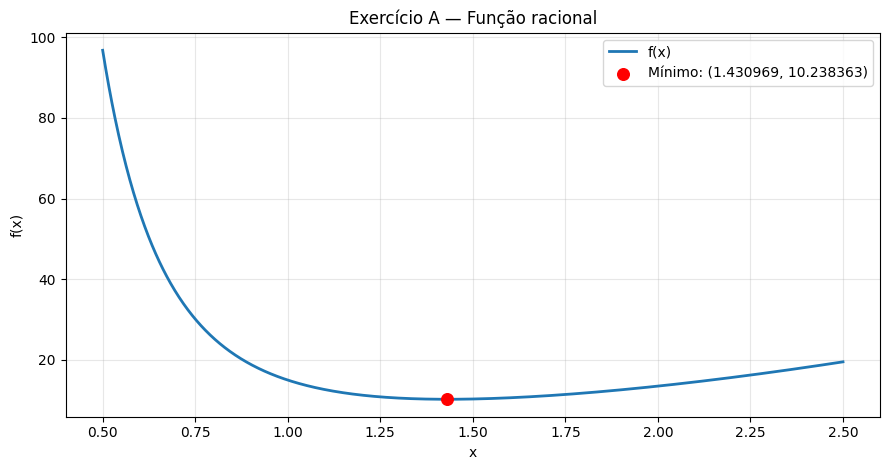

In [13]:
# EXERCÍCIO A — f(x) = 3x² + 12/x³, intervalo (0,5; 2,5)
def f_a(x):
    return 3*x**2 + 12/x**3

resultado_a = minimize_scalar(
    f_a, bounds=(0.5, 2.5), method="bounded", options={"xatol": 1e-12}
)

print("EXERCÍCIO A")
print("Enunciado: minimizar f(x) = 3x² + 12/x³ no intervalo (0,5; 2,5).")
print(f"x mínimo ≈ {resultado_a.x:.8f}")
print(f"f(x mínimo) ≈ {resultado_a.fun:.8f}")
gerar_grafico(f_a, 0.5, 2.5, "Exercício A — Função racional", resultado_a.x)

## 3. Exercício B — Função trigonométrica
Enunciado: Minimizar a função

$f(x)=4x\operatorname{sen}(x)$

no intervalo $(0,\pi)$ e apresentar o gráfico.

Esse exercício tem um detalhe: como o intervalo é aberto, $0$ e $\pi$ não fazem parte dele. A função é positiva dentro do intervalo e se aproxima de zero nas extremidades. Por isso, o ínfimo é zero, mas não há um mínimo atingido.

Mesmo assim, executamos o algoritmo para ver o ponto aproximado que ele encontra. Esse ponto não deve ser confundido com um mínimo matemático do intervalo aberto.

EXERCÍCIO B
Enunciado: minimizar f(x) = 4x sen(x) no intervalo (0; π).
Resultado numérico do algoritmo: x ≈ 0.0000038196
Valor numérico da função: f(x) ≈ 5.835707575332e-11
Ínfimo: 0. Não existe mínimo no intervalo aberto (0; π).
Se fosse [0; π], o valor mínimo seria 0 em x = 0 e x = π.


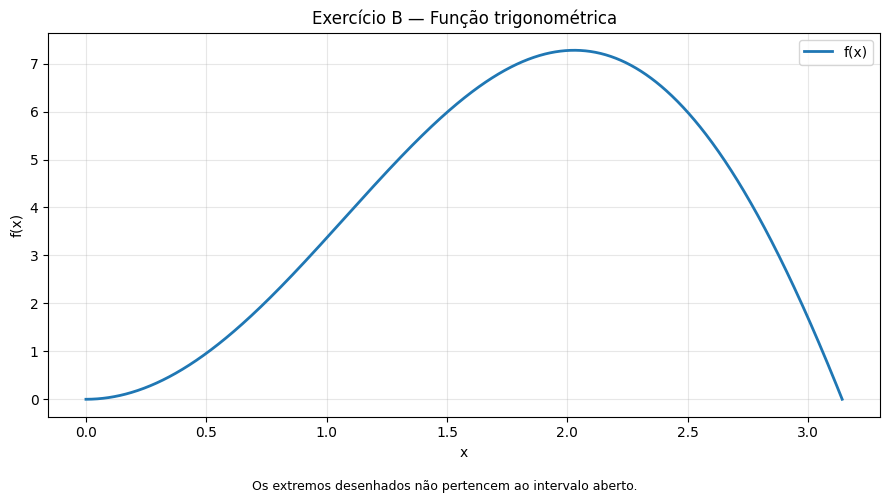


Função: f(x) = 3x² + 12/x³
Intervalo: (0.5, 2.5)
x mínimo = 1.430969
f(x mínimo) = 10.238363


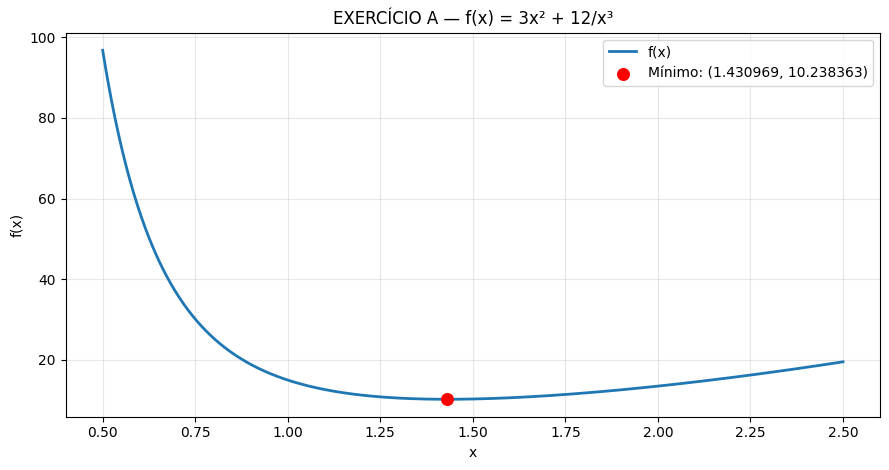

In [14]:
# EXERCÍCIO B — f(x) = 4x sen(x), intervalo (0; pi)
def f_b(x):
    return 4*x*np.sin(x)

resultado_b = minimize_scalar(f_b, bounds=(0, np.pi), method="bounded")

print("EXERCÍCIO B")
print("Enunciado: minimizar f(x) = 4x sen(x) no intervalo (0; π).")
print(f"Resultado numérico do algoritmo: x ≈ {resultado_b.x:.10f}")
print(f"Valor numérico da função: f(x) ≈ {resultado_b.fun:.12e}")
print("Ínfimo: 0. Não existe mínimo no intervalo aberto (0; π).")
print("Se fosse [0; π], o valor mínimo seria 0 em x = 0 e x = π.")

gerar_grafico(f_b, 0, np.pi, "Exercício B — Função trigonométrica",
              observacao="Os extremos desenhados não pertencem ao intervalo aberto.")

# 3.4 Apresentação dos resultados
print("\nFunção: f(x) = 3x² + 12/x³")
print("Intervalo: (0.5, 2.5)")
print(f"x mínimo = {resultado_a.x:.6f}")
print(f"f(x mínimo) = {resultado_a.fun:.6f}")

# 3.5 Gráfico
gerar_grafico(
    f_a, a_a, b_a,
    "EXERCÍCIO A — f(x) = 3x² + 12/x³",
    minimo=resultado_a.x
)

## 4. Exercício C — Função exponencial
Enunciado: Minimizar a função

$f(x)=2(x-3)^2+e^{0{,}5x^2}$

no intervalo $(0,100)$ e apresentar o gráfico.

Neste caso, a exponencial cresce muito rápido e pode causar overflow se tentarmos calcular diretamente até $x=100$. Como a derivada

$f'(x)=4(x-3)+xe^{0{,}5x^2}$

é positiva para $x\geq 3$, a função só cresce a partir daí. Então buscamos o mínimo entre $0$ e $3$, sem alterar a conclusão para o intervalo original. O gráfico também é ampliado nessa região para conseguirmos enxergar o mínimo.

EXERCÍCIO C
Enunciado: minimizar f(x) = 2(x-3)² + exp(0,5x²) em (0; 100).
Intervalo utilizado no cálculo: [0; 3] (com justificativa acima).
x mínimo ≈ 1.59071709
f(x mínimo) ≈ 7.51592415


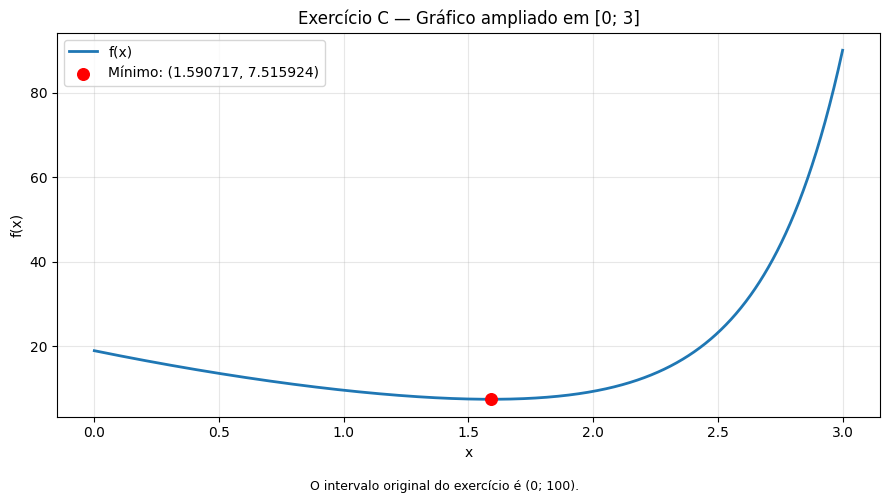

In [15]:
# EXERCÍCIO C — f(x) = 2(x-3)² + exp(0,5x²), intervalo (0; 100)
def f_c(x):
    return 2*(x - 3)**2 + np.exp(0.5*x**2)

# Busca restrita a [0, 3], pois a função cresce para x >= 3.
resultado_c = minimize_scalar(
    f_c, bounds=(0, 3), method="bounded", options={"xatol": 1e-12}
)

print("EXERCÍCIO C")
print("Enunciado: minimizar f(x) = 2(x-3)² + exp(0,5x²) em (0; 100).")
print("Intervalo utilizado no cálculo: [0; 3] (com justificativa acima).")
print(f"x mínimo ≈ {resultado_c.x:.8f}")
print(f"f(x mínimo) ≈ {resultado_c.fun:.8f}")
gerar_grafico(f_c, 0, 3, "Exercício C — Gráfico ampliado em [0; 3]",
              resultado_c.x, "O intervalo original do exercício é (0; 100).")

## 5. Resultados encontrados
No Exercício A, conseguimos encontrar o mínimo dentro do intervalo indicado. No Exercício B, o algoritmo retorna um valor próximo de zero, mas a função não atinge um mínimo no intervalo aberto. No Exercício C, encontramos o mínimo após limitar a busca à região onde ele pode ocorrer.

In [16]:
print("=" * 57)
print("SIMULAÇÃO 1 — RESUMO")
print("=" * 57)
print(f"A) x = {resultado_a.x:.6f}; f(x) = {resultado_a.fun:.6f}")
print("B) ínfimo = 0; não existe mínimo em (0; π)")
print(f"C) x = {resultado_c.x:.6f}; f(x) = {resultado_c.fun:.6f}")

SIMULAÇÃO 1 — RESUMO
A) x = 1.430969; f(x) = 10.238363
B) ínfimo = 0; não existe mínimo em (0; π)
C) x = 1.590717; f(x) = 7.515924
